In [ ]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import ConvVAE, plot_latent_usage
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [ ]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7

train=1085  val=132  test=136


In [ ]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [5]:
model = ConvVAE(latent=64, cond_dim=0).to(device)
init_model(model, train_loader)  # sets Xavier/He weights + band-mean output bias

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=64, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
)

# Train the model & save the best epoch's version

In [6]:
history = fit(
    model,
    train_loader,
    val_loader,
    device,
    epochs=150,
    lr=1e-3,
    beta_max=5e-4,
    anneal_start=50,
    anneal_epochs=50,
    ckpt_path=f"best_vae_fold{split_k}.pt")

epoch   1/150  beta 0.00e+00  train 0.7374  val 0.6247  recon 0.6247  MSE 0.00046  KL 177.26  R2 0.191
epoch   2/150  beta 0.00e+00  train 0.5565  val 0.5067  recon 0.5067  MSE 0.00037  KL 309.63  R2 0.343
epoch   3/150  beta 0.00e+00  train 0.4619  val 0.4134  recon 0.4134  MSE 0.00030  KL 407.13  R2 0.464
epoch   4/150  beta 0.00e+00  train 0.3691  val 0.3444  recon 0.3444  MSE 0.00025  KL 435.66  R2 0.554
epoch   5/150  beta 0.00e+00  train 0.3251  val 0.3145  recon 0.3145  MSE 0.00023  KL 428.29  R2 0.592
epoch   6/150  beta 0.00e+00  train 0.3056  val 0.2977  recon 0.2977  MSE 0.00022  KL 428.39  R2 0.614
epoch   7/150  beta 0.00e+00  train 0.2913  val 0.2860  recon 0.2860  MSE 0.00021  KL 433.22  R2 0.629
epoch   8/150  beta 0.00e+00  train 0.2786  val 0.2736  recon 0.2736  MSE 0.00020  KL 438.41  R2 0.645
epoch   9/150  beta 0.00e+00  train 0.2673  val 0.2632  recon 0.2632  MSE 0.00019  KL 449.32  R2 0.659
epoch  10/150  beta 0.00e+00  train 0.2569  val 0.2526  recon 0.2526  MSE

# Evaluate training history

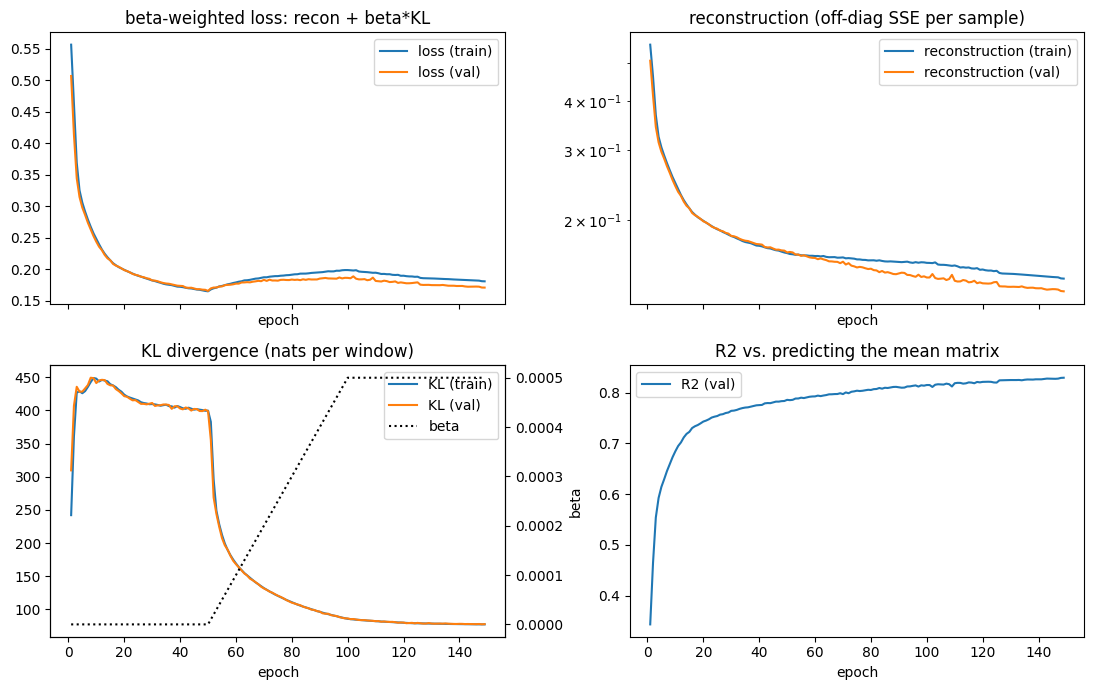

: 

In [ ]:
g = plot_history(history, skip=1)
g.show()